In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [70]:
CRSP_FILE = "crsp_2023.csv"           
FF_FILE = "FamaFrench2023.CSV"         
RF_ANNUAL = 0.045    

In [71]:
crsp = pd.read_csv(CRSP_FILE)
crsp.columns = crsp.columns.str.strip().str.lower()   
print(crsp.head())
print("CRSP shape:", crsp.shape)

   permno  hdrcusip ticker  permco    dlycaldt    dlyret
0   10107  59491810   MSFT    8048  2023-01-03 -0.001001
1   10107  59491810   MSFT    8048  2023-01-04 -0.043743
2   10107  59491810   MSFT    8048  2023-01-05 -0.029638
3   10107  59491810   MSFT    8048  2023-01-06  0.011785
4   10107  59491810   MSFT    8048  2023-01-09  0.009736
CRSP shape: (3751, 6)


In [72]:
crsp = crsp.drop(columns=["permno"], errors="ignore")

In [73]:
date_col = "dlycaldt" if "dlycaldt" in crsp.columns else "date"
crsp = crsp.rename(columns={date_col: "date"})

In [74]:
crsp = crsp.drop_duplicates(subset=["ticker", "date"])

In [75]:
crsp["date"] = pd.to_datetime(crsp["date"])
crsp["dlyret"] = pd.to_numeric(crsp["dlyret"], errors="coerce")
print(crsp.dtypes)

hdrcusip            object
ticker              object
permco               int64
date        datetime64[ns]
dlyret             float64
dtype: object


In [76]:
print("Unique tickers:", crsp["ticker"].nunique())
counts = crsp.groupby("ticker")["dlyret"].count()
print(counts)
n_days = crsp["date"].nunique()
print("Trading days:", n_days, "| rows:", len(crsp),
      "| expected rows:", n_days * crsp["ticker"].nunique())
if counts.nunique() != 1:
    print("WARNING: unbalanced panel, some tickers are missing days:")
    print(counts[counts != n_days])

Unique tickers: 15
ticker
AAPL    250
AMZN    250
CMG     250
COST    250
DELL    250
F       250
H       250
MRNA    250
MSFT    250
NFLX    250
PEP     250
PFE     250
SPOT    250
TSLA    250
XRX     250
Name: dlyret, dtype: int64
Trading days: 250 | rows: 3750 | expected rows: 3750


In [77]:
print(crsp["dlyret"].describe())
crsp = crsp.dropna(subset=["dlyret", "ticker"])

count    3750.000000
mean        0.001483
std         0.020935
min        -0.142560
25%        -0.009243
50%         0.001261
75%         0.011444
max         0.212482
Name: dlyret, dtype: float64


In [78]:
ff = pd.read_csv(FF_FILE)
ff.columns = ff.columns.str.strip()
print(ff.head())
print(ff.describe())
print(ff.dtypes)

       date  Mkt-RF   SMB   HML     RF
0  1/3/2023   -0.48  0.08 -0.12  0.017
1  1/4/2023    0.81  0.54  0.05  0.017
2  1/5/2023   -1.14 -0.18  1.22  0.017
3  1/6/2023    2.21 -0.06  0.05  0.017
4  1/9/2023    0.04  0.54 -1.24  0.017
          Mkt-RF         SMB         HML          RF
count  250.00000  250.000000  250.000000  250.000000
mean     0.07864   -0.005000   -0.042320    0.019144
std      0.86217    0.676886    0.761922    0.002056
min     -2.16000   -1.650000   -3.520000    0.016000
25%     -0.44750   -0.445000   -0.530000    0.017000
50%      0.05000   -0.030000   -0.070000    0.020000
75%      0.64000    0.300000    0.487500    0.021000
max      2.21000    2.990000    2.250000    0.022000
date       object
Mkt-RF    float64
SMB       float64
HML       float64
RF        float64
dtype: object


In [79]:
first_col = ff.columns[0]
ff = ff.rename(columns={first_col: "date"})

In [80]:
if pd.api.types.is_numeric_dtype(ff["date"]):
    ff["date"] = pd.to_datetime(ff["date"].astype(int).astype(str), format="%Y%m%d")
else:
    ff["date"] = pd.to_datetime(ff["date"], format="%m/%d/%Y")

In [81]:
factor_cols = ["Mkt-RF", "SMB", "HML", "RF"]
ff[factor_cols] = ff[factor_cols] / 100

In [82]:
df = pd.merge(crsp, ff, on="date", how="inner")
print("Merged shape:", df.shape)

Merged shape: (3750, 9)


In [83]:
df["RP"] = df["dlyret"] - df["RF"]

In [84]:
def run_ols(data, x_cols):
    """OLS of RP on the given factor columns, with an intercept (alpha)."""
    X = sm.add_constant(data[x_cols])   # add_constant creates the alpha term
    y = data["RP"]
    return sm.OLS(y, X).fit()

In [85]:
capm_models = {t: run_ols(g, ["Mkt-RF"]) for t, g in df.groupby("ticker")}
 
params1 = pd.DataFrame({t: m.params for t, m in capm_models.items()}).T
params1 = params1.rename(columns={"const": "alpha1", "Mkt-RF": "betamkt1"})
params1.index.name = "ticker"
params1 = params1.reset_index()
 
rsq1 = pd.Series({t: m.rsquared for t, m in capm_models.items()})
rsq1.index.name = "ticker"
rsq1 = rsq1.reset_index(name="rsq1")

In [86]:
ff_models = {t: run_ols(g, ["Mkt-RF", "SMB", "HML"]) for t, g in df.groupby("ticker")}
 
params2 = pd.DataFrame({t: m.params for t, m in ff_models.items()}).T
params2 = params2.rename(columns={"const": "alpha2", "Mkt-RF": "betamkt2",
                                  "SMB": "betasmb", "HML": "betahml"})
params2.index.name = "ticker"
params2 = params2.reset_index()
 
rsq2 = pd.Series({t: m.rsquared for t, m in ff_models.items()})
rsq2.index.name = "ticker"
rsq2 = rsq2.reset_index(name="rsq2")

In [87]:
adjr2 = pd.DataFrame({
    "ticker": list(capm_models.keys()),
    "adj_rsq1": [m.rsquared_adj for m in capm_models.values()],
    "adj_rsq2": [ff_models[t].rsquared_adj for t in capm_models.keys()],
})

In [88]:
std = df.groupby("ticker")["dlyret"].std().reset_index(name="std_dlyret")
std["std_dlyret"] = std["std_dlyret"] * np.sqrt(n_days)
 
df = df.sort_values(["ticker", "date"])
df["HPR"] = df.groupby("ticker")["dlyret"].transform(lambda r: (1 + r).cumprod() - 1)
hpr = df.groupby("ticker")["HPR"].last().reset_index()

        alpha1  betamkt1  alpha2  betamkt2  betasmb  betahml  std_dlyret  \
ticker                                                                     
AAPL    0.0007    1.0366  0.0004    1.1003  -0.2831  -0.3730      0.2022   
AMZN    0.0012    1.4642  0.0009    1.4529  -0.0962  -0.8596      0.3288   
CMG     0.0014    0.7503  0.0011    0.6681   0.1853  -0.6584      0.2592   
COST    0.0009    0.7558  0.0007    0.7970  -0.1829  -0.2387      0.1903   
DELL    0.0020    0.9428  0.0020    1.0232  -0.2428   0.2544      0.3461   
F      -0.0005    1.3939 -0.0001    1.2461   0.5896   0.4367      0.3510   
H       0.0006    1.1555  0.0007    1.1035   0.2265   0.2741      0.2996   
MRNA   -0.0030    1.0534 -0.0028    0.8545   0.6980  -0.0155      0.4498   
MSFT    0.0009    1.0742  0.0005    1.1650  -0.4462  -0.8010      0.2497   
NFLX    0.0011    1.2575  0.0008    1.2470  -0.0703  -0.6787      0.3736   
PEP    -0.0005    0.3248 -0.0006    0.4492  -0.4310   0.0443      0.1495   
PFE    -0.00

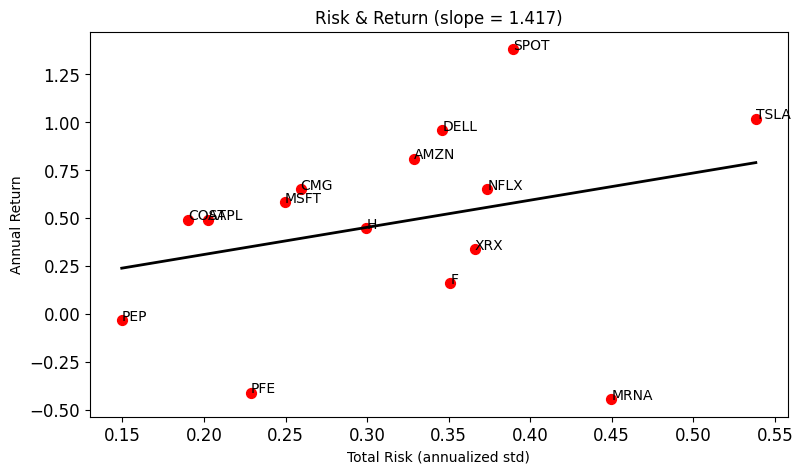

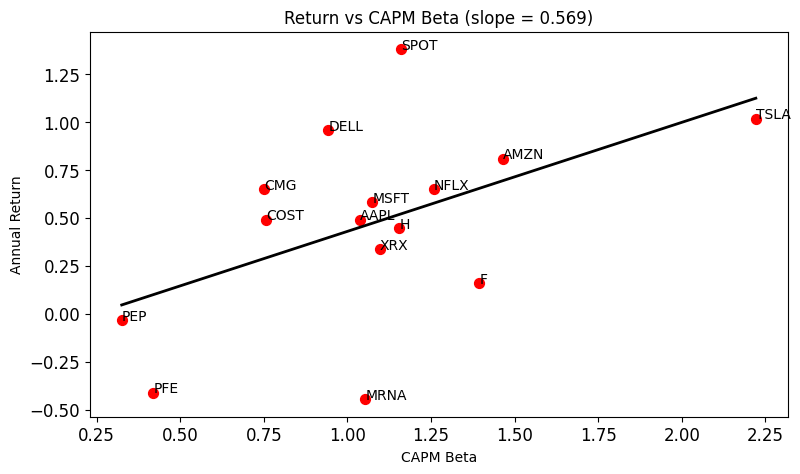

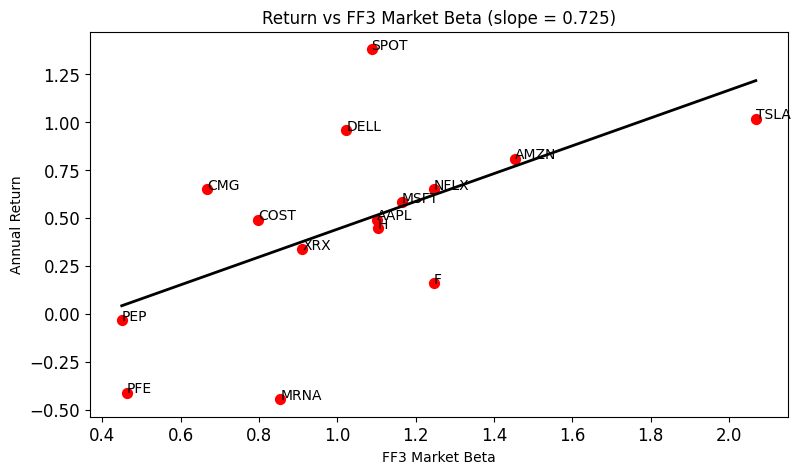


Beta correlations:
          betamkt1  betamkt2  betasmb  betahml
betamkt1     1.000     0.975    0.441   -0.312
betamkt2     0.975     1.000    0.235   -0.405
betasmb      0.441     0.235    1.000    0.403
betahml     -0.312    -0.405    0.403    1.000


In [89]:
rr = (params1.merge(params2, on="ticker")
             .merge(std, on="ticker")
             .merge(hpr, on="ticker"))
rr.set_index("ticker", inplace=True)
print(rr.round(4))
 
 
def scatter_with_line(x_col, xlabel, title):
    """Scatter of annual return vs a risk measure, tickers labeled, OLS line fitted."""
    rr.plot.scatter(x=x_col, y="HPR", figsize=(9, 5), s=50, fontsize=12, color="red")
    for i in rr.index:   
        plt.annotate(i, xy=(rr.loc[i, x_col], rr.loc[i, "HPR"]), size=10)
    slope, intercept = np.polyfit(rr[x_col], rr["HPR"], 1)   # straight line fit
    xs = np.sort(rr[x_col].values)
    plt.plot(xs, slope * xs + intercept, color="black", linewidth=2)
    plt.xlabel(xlabel, fontsize=10)
    plt.ylabel("Annual Return", fontsize=10)
    plt.title(f"{title} (slope = {slope:.3f})", fontsize=12)
    plt.show()
    return slope
 
slope_std = scatter_with_line("std_dlyret", "Total Risk (annualized std)", "Risk & Return")
slope_b1 = scatter_with_line("betamkt1", "CAPM Beta", "Return vs CAPM Beta")
slope_b2 = scatter_with_line("betamkt2", "FF3 Market Beta", "Return vs FF3 Market Beta")
 
beta_cols = ["betamkt1", "betamkt2", "betasmb", "betahml"]
print("\nBeta correlations:")
print(rr[beta_cols].corr().round(3))

In [90]:
rr["Sharpe"] = (rr["HPR"] - RF_ANNUAL) / rr["std_dlyret"]
rr["Treynor"] = (rr["HPR"] - RF_ANNUAL) / rr["betamkt1"]
 
rr["Sharpe_rank"] = rr["Sharpe"].rank(ascending=False).astype(int)
rr["Treynor_rank"] = rr["Treynor"].rank(ascending=False).astype(int)
 
print("\nRanked by Sharpe:")
print(rr.sort_values("Sharpe", ascending=False)[["HPR", "std_dlyret", "Sharpe", "Sharpe_rank"]].round(3))
print("\nRanked by Treynor:")
print(rr.sort_values("Treynor", ascending=False)[["HPR", "betamkt1", "Treynor", "Treynor_rank"]].round(3))


Ranked by Sharpe:
          HPR  std_dlyret  Sharpe  Sharpe_rank
ticker                                        
SPOT    1.380       0.389   3.430            1
DELL    0.958       0.346   2.639            2
COST    0.490       0.190   2.337            3
CMG     0.648       0.259   2.327            4
AMZN    0.809       0.329   2.323            5
AAPL    0.490       0.202   2.201            6
MSFT    0.582       0.250   2.150            7
TSLA    1.017       0.538   1.806            8
NFLX    0.651       0.374   1.622            9
H       0.448       0.300   1.344           10
XRX     0.336       0.366   0.795           11
F       0.158       0.351   0.322           12
PEP    -0.033       0.150  -0.522           13
MRNA   -0.446       0.450  -1.092           14
PFE    -0.412       0.229  -1.999           15

Ranked by Treynor:
          HPR  betamkt1  Treynor  Treynor_rank
ticker                                        
SPOT    1.380     1.161    1.150             1
DELL    0.958     0.9

In [91]:
mkt_daily = ff.loc[ff["date"].dt.year == 2023, "Mkt-RF"] + ff.loc[ff["date"].dt.year == 2023, "RF"]
mkt_hpr = (1 + mkt_daily).prod() - 1
print(f"\nMarket HPR 2023: {mkt_hpr:.2%}")
print(f"Slopes -> std: {slope_std:.3f}, CAPM beta: {slope_b1:.3f}, FF3 beta: {slope_b2:.3f}")
print(f"Mean R2 -> CAPM: {rsq1['rsq1'].mean():.3f}, FF3: {rsq2['rsq2'].mean():.3f}")
print(f"Mean adj R2 -> CAPM: {adjr2['adj_rsq1'].mean():.3f}, FF3: {adjr2['adj_rsq2'].mean():.3f}")
print(f"Best Sharpe: {rr['Sharpe'].idxmax()} | Worst Sharpe: {rr['Sharpe'].idxmin()}")


Market HPR 2023: 26.50%
Slopes -> std: 1.417, CAPM beta: 0.569, FF3 beta: 0.725
Mean R2 -> CAPM: 0.231, FF3: 0.296
Mean adj R2 -> CAPM: 0.228, FF3: 0.288
Best Sharpe: SPOT | Worst Sharpe: PFE


In [93]:
print(rr["Sharpe"].sort_values(ascending=False).round(3))

ticker
SPOT    3.430
DELL    2.639
COST    2.337
CMG     2.327
AMZN    2.323
AAPL    2.201
MSFT    2.150
TSLA    1.806
NFLX    1.622
H       1.344
XRX     0.795
F       0.322
PEP    -0.522
MRNA   -1.092
PFE    -1.999
Name: Sharpe, dtype: float64


In [ ]:
# Market performance in 2023 was strong with a market return of about 26.5%. 
# Yes, all three fitted slopes are positive (std 1.42, CAPM beta 0.57, FF3 beta 0.73)
# The FF# market beta line is steeper.
# Fama-French with an average R^2 of 0.296 vs 0.231 for CAPM. Adjusted R^2 agrees (0.288 vs 0.228), so the gain is not simply from adding more variables.
# Based on the Sharpe ratios, SPOT performed the best (3.43) and PFE performed the worst (-1.99)